### 实验3 卷积神经网络计算机视觉基础 (1 MNIST)

#### 一、基本实现过程
##### 1.1 基本设置
（1）导入torch等第三方库

In [ ]:
import random
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.nn.functional as F # 函数式接口模块
from torch.utils.data import DataLoader, TensorDataset # 数据集组织，以便后面batch划分
import torch.optim as optim # 优化器

import json
import time
from pathlib import Path
# 将训练历史、验证结果和测试比较表按表格格式显示
from IPython.display import display
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# 所有结果放在当前实验目录下，重复运行时覆盖同名结果。
OUTPUT_DIR = Path('outputs')
OUTPUT_DIR.mkdir(exist_ok=True)
torch.set_num_threads(4) 


（2）设置图表显示

In [ ]:
# 设置中文字体和图像清晰度，统一后续训练曲线的显示风格
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker  # 导入刻度格式化模块
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC']  # 支持中文字体
plt.rcParams['figure.dpi'] = 300   # Notebook 中显示的清晰度
plt.rcParams['savefig.dpi'] = 300  # 保存图片的清晰度
plt.rcParams['font.size'] = 12

（3）观察设备情况，以便后面使用GPU

In [3]:
# 优先使用GPU；后面的模型与数据均移动到该设备。
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"正在使用的设备: {device}")

正在使用的设备: cuda


（4）设置固定随机种子，以便复现

In [4]:
# 固定Python、NumPy和PyTorch的随机种子，便于重复对比。
# 设置随机种子（不含对batch划分的设置）
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)                # PyTorch CPU随机数
    torch.cuda.manual_seed(seed)           # PyTorch 当前GPU随机数
    torch.cuda.manual_seed_all(seed)       # PyTorch 所有GPU随机数
    torch.backends.cudnn.deterministic = True # 强制CuDNN使用确定性算法
    torch.backends.cudnn.benchmark = False # 关闭CuDNN的自动寻找最优算法

set_seed(42)

##### 1.2 数据导入与预处理
（1）导入数据集并观察形状

In [ ]:
data = np.load('data/mnist.npz')
print(data.files)

['x_test', 'x_train', 'y_train', 'y_test']


In [ ]:
# 分别取出原始训练集与测试集，检查图像和标签的样本维度
x_train, x_test, y_train, y_test = data['x_train'], data['x_test'], data['y_train'], data['y_test']
print(f"训练集特征形状: {x_train.shape}")
print(f"训练集标签形状: {y_train.shape}")
print(f"测试集特征形状: {x_test.shape}")
print(f"测试集标签形状: {y_test.shape}")

训练集特征形状: (60000, 28, 28)
训练集标签形状: (60000,)
测试集特征形状: (10000, 28, 28)
测试集标签形状: (10000,)


（2）从原训练数据中固定划分 20% 为验证集

随机种子为 42，所有 epoch 使用同一验证集；测试集单独保留。

In [7]:
# 从原训练集中按类别分层划出20%的固定验证集。
val_ratio = 0.2
x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train, test_size=val_ratio, random_state=42, stratify=y_train
)
print(f"训练集样本数: {len(y_train)}")
print(f"验证集样本数: {len(y_val)}")

训练集样本数: 48000
验证集样本数: 12000


（3）调整图像形状并归一化

In [8]:
# 补充单通道维度，使输入符合Conv2d要求的N×C×H×W格式。
x_train = x_train.reshape(-1, 1, 28, 28)
x_val = x_val.reshape(-1, 1, 28, 28)
x_test = x_test.reshape(-1, 1, 28, 28)

print(f"训练集特征形状: {x_train.shape}")
print(f"验证集特征形状: {x_val.shape}")
print(f"测试集特征形状: {x_test.shape}")

# 数据范围为 [0, 255]，训练、验证、测试使用相同的归一化方式。
x_train = x_train.astype('float32') / 255
x_val = x_val.astype('float32') / 255
x_test = x_test.astype('float32') / 255

# torch 框架下，无需对无序类别标签作 one-hot 处理。

训练集特征形状: (48000, 1, 28, 28)
验证集特征形状: (12000, 1, 28, 28)
测试集特征形状: (10000, 1, 28, 28)


（4）将训练、验证、测试数据转换为 torch 张量

In [9]:
# 把图像转换为浮点张量，把类别标签转换为交叉熵要求的long张量。
x_train_tensor = torch.tensor(x_train, dtype=torch.float32).to(device)
x_val_tensor = torch.tensor(x_val, dtype=torch.float32).to(device)
x_test_tensor = torch.tensor(x_test, dtype=torch.float32).to(device)

# 无序类别标签必须使用 torch.long。
y_train_tensor = torch.tensor(y_train, dtype=torch.long).to(device)
y_val_tensor = torch.tensor(y_val, dtype=torch.long).to(device)
y_test_tensor = torch.tensor(y_test, dtype=torch.long).to(device)

##### 1.3 网络结构定义与模型训练

Baseline 参数汇总：

| 模型 | 输入 | 隐藏结构 | 输出 | 激活函数 | dropout | epoch | batch | 学习率 | 优化器 | Loss |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| CNN | 1×28×28 | Conv32→Pool→Conv64→Pool→Linear128 | 10 | ReLU | 不设置 | 15 | 128 | 0.001 | RMSprop | 交叉熵 |
| ANN（对照） | 展平为784 | Linear512 | 10 | ReLU | 不设置 | 15 | 128 | 0.001 | RMSprop | 交叉熵 |

两个模型使用同一训练／验证划分与 batch 顺序，每个模型训练前重新设置随机种子。
CNN 输出原始 logits，交叉熵内部处理归一化。


（1）网络结构定义

In [10]:
# 定义两组卷积、激活和池化组成的MNIST基础CNN。
# 自定义CNN结构
class CNN(nn.Module):

    def __init__(self):
        super(CNN, self).__init__()

        # 第一层卷积：1个输入通道，32个输出通道
        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        # 第二层卷积：32个输入通道，64个输出通道
        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3,
            padding=1
        )

        # 最大池化：尺寸缩小一半
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # 全连接层
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        # 第一组卷积 + 激活 + 池化
        x = self.conv1(x)
        x = F.relu(x)
        x = self.pool(x)

        # 第二组卷积 + 激活 + 池化
        x = self.conv2(x)
        x = F.relu(x)
        x = self.pool(x)

        # 展平
        x = torch.flatten(x, start_dim=1)

        # 全连接分类
        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x


（2）创建model对象，设置loss函数与优化器

In [11]:
# 为基础CNN创建交叉熵损失和RMSprop优化器。
model = CNN().to(device) # 先移动到设备，再为该模型创建优化器
criterion = nn.CrossEntropyLoss() # 交叉熵损失
optimizer = optim.RMSprop(model.parameters(), lr=0.001) # 延续原代码的优化器


（3）每个 epoch 结束后记录训练集与固定验证集的 Loss、Acc，并保存验证集表现最好的权重。
两组指标均使用当前 epoch 结束时的同一模型，在评估模式下计算。训练共15轮，测试集只在所有候选训练完成后评估。


In [12]:
# 训练指定模型，并依据固定验证集保存、恢复最佳轮次的权重。
def train_model(model, epochs, batch, optimizer, run_name):
    model = model.to(device)
    # 为每个模型重建相同的批次随机顺序。
    g = torch.Generator().manual_seed(42)
    train_dataset = TensorDataset(x_train_tensor, y_train_tensor)
    val_dataset = TensorDataset(x_val_tensor, y_val_tensor)
    train_loader = DataLoader(train_dataset, batch_size=batch, shuffle=True, generator=g)
    # 评估时不打乱样本，训练集和验证集均使用固定样本计算指标。
    train_eval_loader = DataLoader(train_dataset, batch_size=batch, shuffle=False)
    val_loader = DataLoader(val_dataset, batch_size=batch, shuffle=False)
    # 记录每轮结果，并初始化最佳验证指标。
    loss_result = []
    best_acc, best_loss, best_epoch = -1.0, float('inf'), 0
    checkpoint = OUTPUT_DIR / f'{run_name}_best.pt'
    # GPU运算是异步的，同步后再开始计时。
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()

    for epoch in range(epochs):
        model.train() # 切换为训练模式，允许参数通过梯度更新
        for batch_x, batch_y in train_loader:
            # 图像与标签必须和模型位于同一设备。
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad() # 清空上一批次残留的梯度
            preds_y = model(batch_x) # 前向传播，输出各类别的logits
            loss_train = criterion(preds_y, batch_y)
            loss_train.backward() # 反向传播，计算各参数的梯度
            optimizer.step() # 根据梯度更新当前模型的参数

        # 同一个 epoch 结束后，在 eval 模式下计算训练集和验证集指标。
        epoch_result = {'Epoch': epoch + 1}
        model.eval()
        with torch.no_grad():
            for split, loader in [('Train', train_eval_loader), ('Val', val_loader)]:
                total_loss_sum, correct, sample_num = 0.0, 0, 0
                for batch_x, batch_y in loader:
                    batch_x = batch_x.to(device)
                    batch_y = batch_y.to(device)
                    preds_y = model(batch_x)
                    loss = criterion(preds_y, batch_y)
                    # 按批次样本数加权，避免最后一个小batch影响平均Loss。
                    total_loss_sum += loss.item() * batch_y.size(0)
                    correct += (preds_y.argmax(dim=1) == batch_y).sum().item()
                    sample_num += batch_y.size(0)
                epoch_result[f'{split}_Loss'] = total_loss_sum / sample_num
                epoch_result[f'{split}_Acc'] = correct / sample_num

        # 仅依据验证集选权重；准确率相同时，选择验证 Loss 较小的轮次。
        val_acc, val_loss = epoch_result['Val_Acc'], epoch_result['Val_Loss']
        if val_acc > best_acc or (val_acc == best_acc and val_loss < best_loss):
            best_acc, best_loss, best_epoch = val_acc, val_loss, epoch + 1
            torch.save(model.state_dict(), checkpoint)

        loss_result.append(epoch_result)
        print(
            f"{run_name} | Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {epoch_result['Train_Loss']:.4f}, "
            f"Train Acc: {epoch_result['Train_Acc']:.2%} | "
            f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2%}", flush=True
        )

    if device.type == 'cuda':
        torch.cuda.synchronize()
    seconds = time.perf_counter() - start
    # 训练结束后恢复最佳验证轮次，后面的测试及保存均使用这组权重。
    model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
    model.eval()
    # 保存比较表需要的最佳轮次与耗时，并把完整历史写入CSV。
    model.best_epoch = best_epoch
    model.training_seconds = seconds
    history = pd.DataFrame(loss_result)
    history.to_csv(OUTPUT_DIR / f'{run_name}_history.csv', index=False)
    print(f'{run_name}: 最佳轮次 {best_epoch}，验证 Acc {best_acc:.2%}，耗时 {seconds:.1f}s')
    return history


In [13]:
# 训练基础CNN，保存结果表，供后续与全连接网络对比。
train_result_df = train_model(model, epochs=15, batch=128, optimizer=optimizer, run_name='CNN')
display(train_result_df.style.format({
    'Train_Loss': '{:.4f}', 'Train_Acc': '{:.2%}',
    'Val_Loss': '{:.4f}', 'Val_Acc': '{:.2%}'
}).hide(axis='index'))
models = {'CNN': model}
results_dict = {'CNN': train_result_df}


CNN | Epoch 1/15 | Train Loss: 0.1066, Train Acc: 96.50% | Val Loss: 0.1172, Val Acc: 96.29%


CNN | Epoch 2/15 | Train Loss: 0.0379, Train Acc: 98.90% | Val Loss: 0.0517, Val Acc: 98.40%


CNN | Epoch 3/15 | Train Loss: 0.0309, Train Acc: 99.07% | Val Loss: 0.0503, Val Acc: 98.40%


CNN | Epoch 4/15 | Train Loss: 0.0201, Train Acc: 99.39% | Val Loss: 0.0405, Val Acc: 98.74%


CNN | Epoch 5/15 | Train Loss: 0.0244, Train Acc: 99.19% | Val Loss: 0.0558, Val Acc: 98.50%


CNN | Epoch 6/15 | Train Loss: 0.0111, Train Acc: 99.70% | Val Loss: 0.0411, Val Acc: 98.78%


... (7 outputs left out)

CNN | Epoch 14/15 | Train Loss: 0.0046, Train Acc: 99.85% | Val Loss: 0.0535, Val Acc: 98.91%


CNN | Epoch 15/15 | Train Loss: 0.0015, Train Acc: 99.95% | Val Loss: 0.0576, Val Acc: 98.96%


CNN: 最佳轮次 15，验证 Acc 98.96%，耗时 7.4s


Epoch,Train_Loss,Train_Acc,Val_Loss,Val_Acc
1,0.1066,96.50%,0.1172,96.29%
2,0.0379,98.90%,0.0517,98.40%
3,0.0309,99.07%,0.0503,98.40%
4,0.0201,99.39%,0.0405,98.74%
5,0.0244,99.19%,0.0558,98.50%
6,0.0111,99.70%,0.0411,98.78%
7,0.0089,99.73%,0.0407,98.91%
8,0.0097,99.66%,0.0489,98.72%
9,0.0045,99.88%,0.0448,98.85%
10,0.0035,99.90%,0.0457,98.78%


（4）绘制 Baseline 的训练集、验证集 Loss 与 Acc 曲线，查看收敛和泛化情况

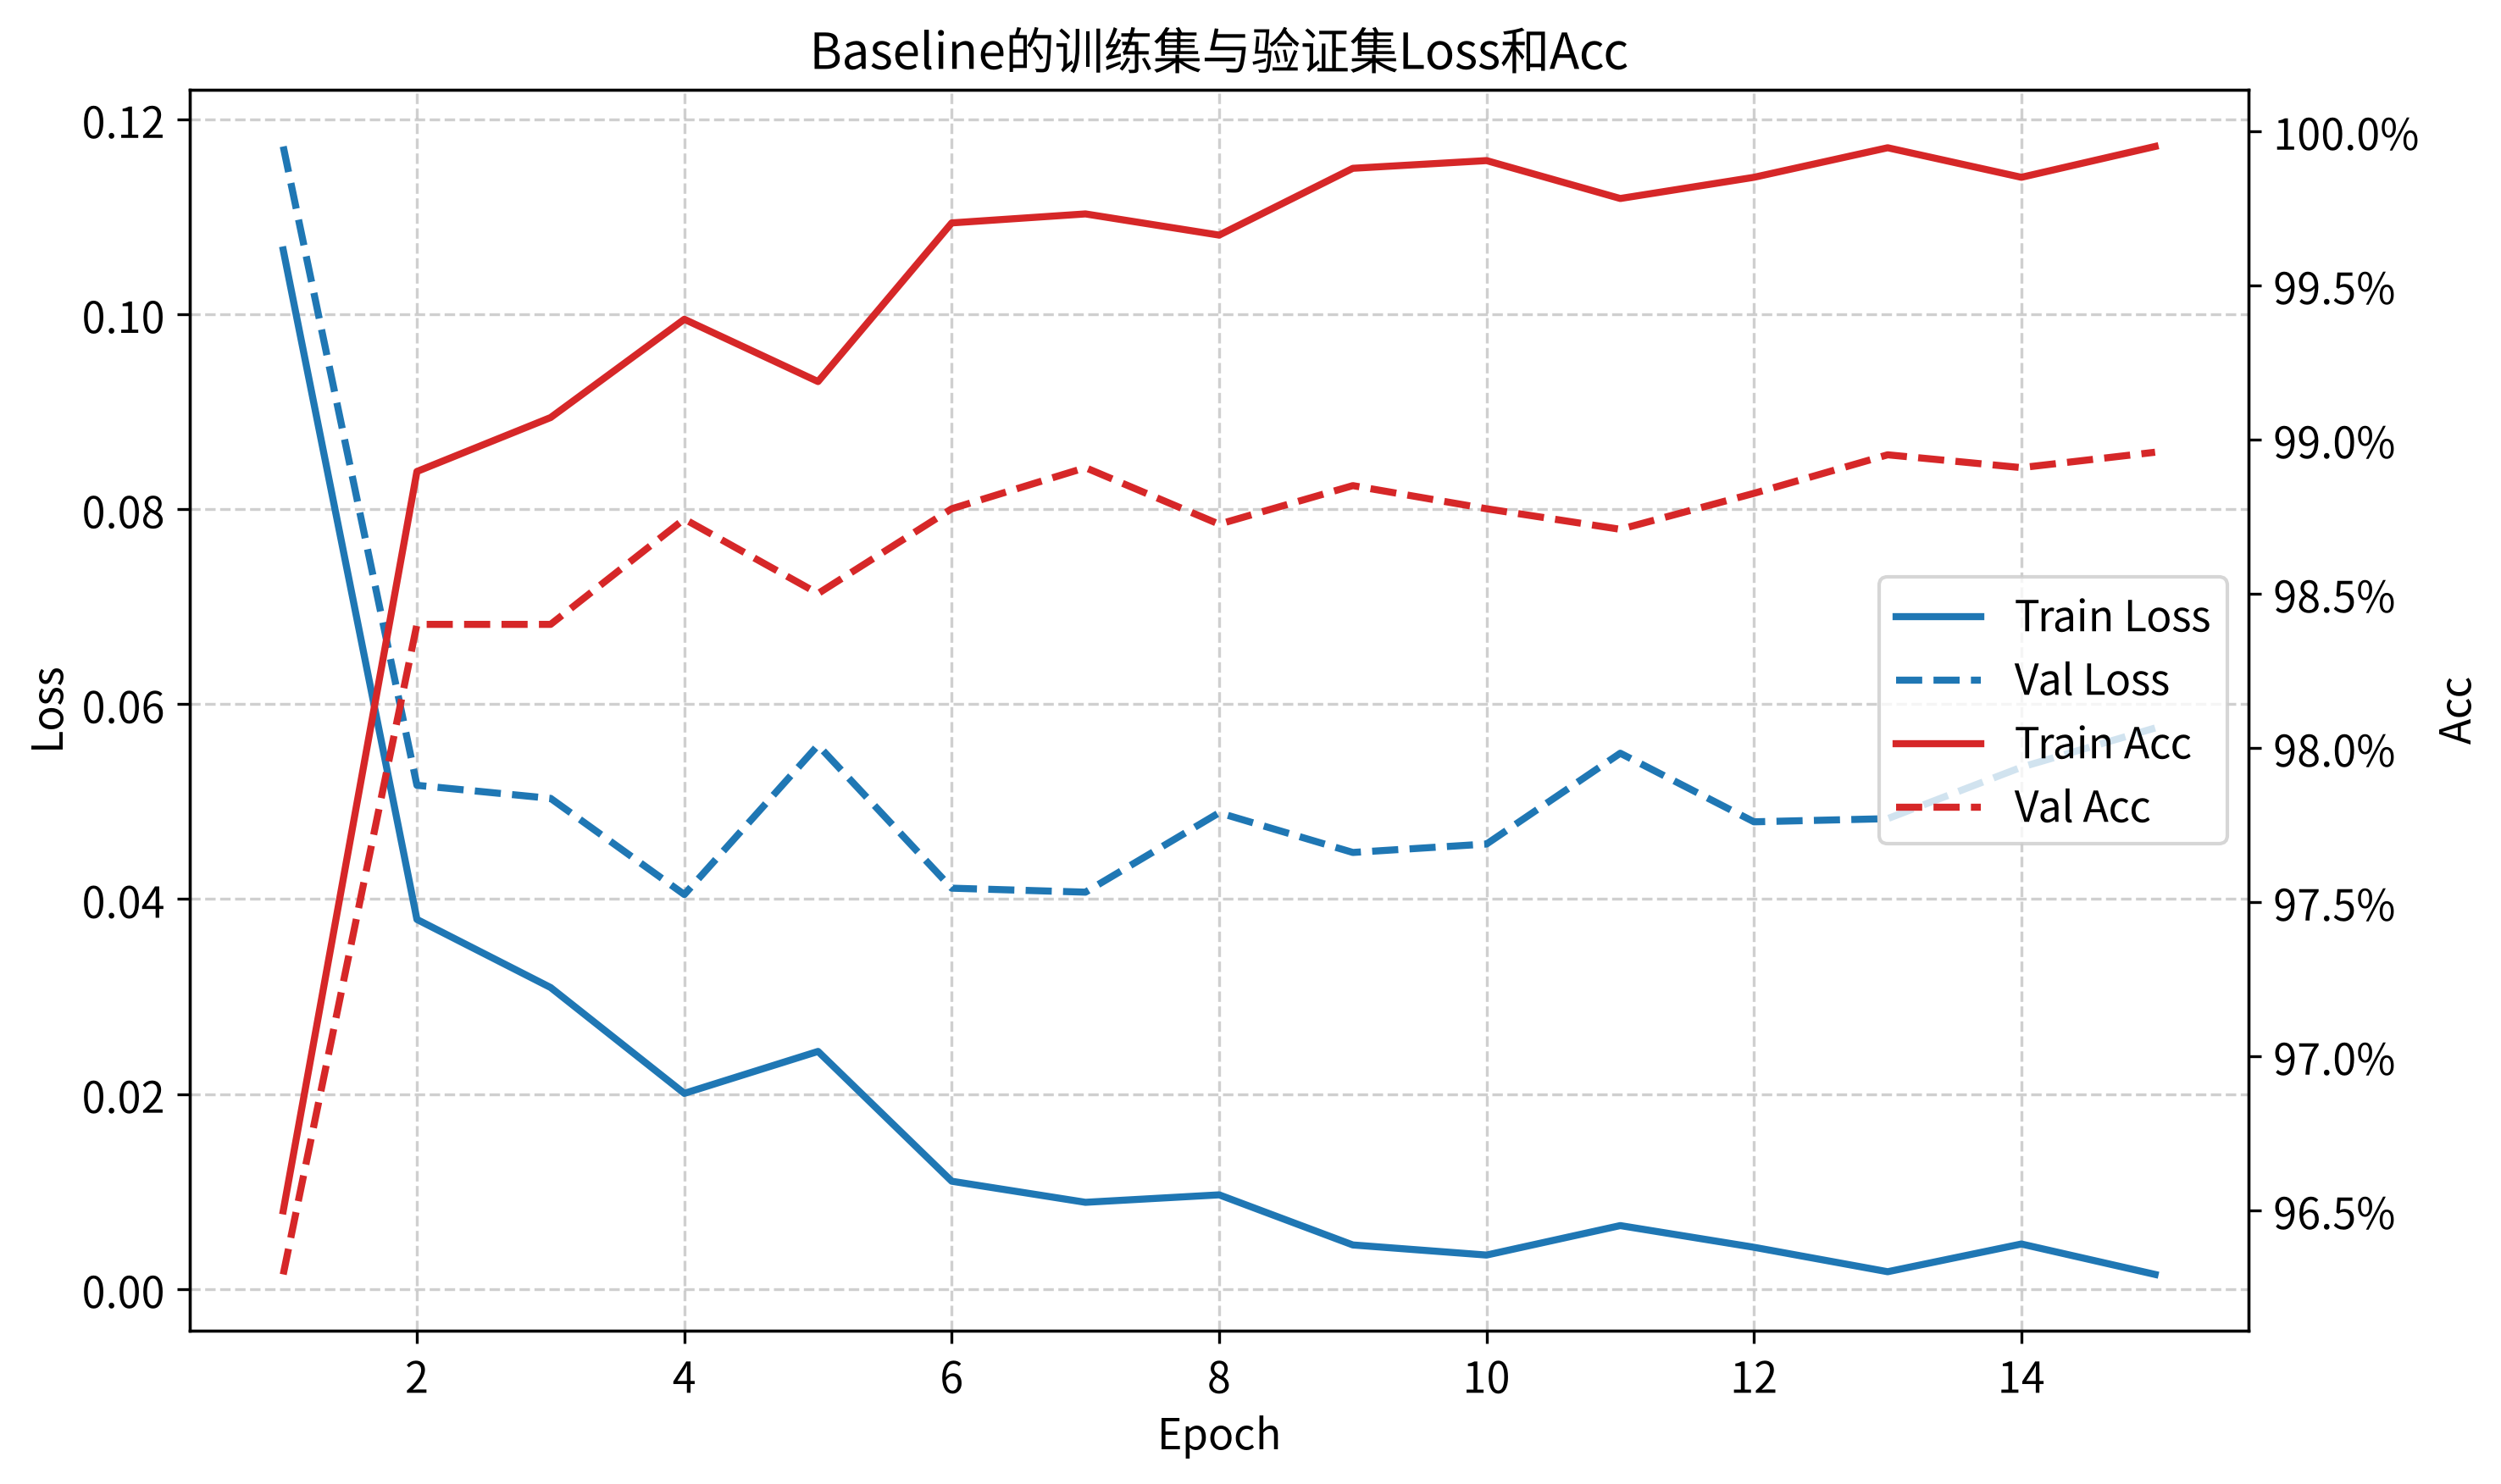

In [14]:
# 在同一张图上显示训练／验证Loss与Acc，观察收敛及泛化差距。
# 分别绘制训练集、验证集的 Loss 与 Acc（实线：训练；虚线：验证）。
epochs = range(1, len(train_result_df) + 1)
fig, ax1 = plt.subplots(figsize=(10, 6))

line1 = ax1.plot(epochs, train_result_df['Train_Loss'],
                 label='Train Loss', color='tab:blue', linewidth=2)
line2 = ax1.plot(epochs, train_result_df['Val_Loss'],
                 label='Val Loss', color='tab:blue', linestyle='--', linewidth=2)
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Loss', fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.6)

ax2 = ax1.twinx()
line3 = ax2.plot(epochs, train_result_df['Train_Acc'],
                 label='Train Acc', color='tab:red', linewidth=2)
line4 = ax2.plot(epochs, train_result_df['Val_Acc'],
                 label='Val Acc', color='tab:red', linestyle='--', linewidth=2)
ax2.set_ylabel('Acc', fontsize=12)
ax2.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0, decimals=1))

lines = line1 + line2 + line3 + line4
ax1.legend(lines, [line.get_label() for line in lines], loc='center right', fontsize=12)
plt.title('Baseline的训练集与验证集Loss和Acc', fontsize=14)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'baseline_curves.png', bbox_inches='tight')
plt.show()


#### 二、全连接网络对照实验
（1）使用前面实验中的单隐藏层 ANN：784→512→10。
保持数据、优化器、学习率、batch 和轮数相同，比较卷积提取局部空间特征与全连接展平输入的差异。


In [15]:
# 定义784→512→10的全连接网络，并按与CNN相同的条件训练。
class ANN(nn.Module):
    def __init__(self):
        super(ANN, self).__init__()
        self.fc1 = nn.Linear(28 * 28, 512) # 展平后的784个像素映射到隐藏层
        self.fc2 = nn.Linear(512, 10) # 输出10个数字类别的logits

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

# 使用与CNN相同的随机种子、优化器、学习率、batch和训练轮数。
set_seed(42)
ann_model = ANN().to(device)
ann_optimizer = optim.RMSprop(ann_model.parameters(), lr=0.001)
ann_result_df = train_model(ann_model, epochs=15, batch=128,
                            optimizer=ann_optimizer, run_name='ANN')
# 将训练后的模型和历史加入统一的对比结果。
models['ANN'] = ann_model
results_dict['ANN'] = ann_result_df
display(ann_result_df.style.format({
    'Train_Loss': '{:.4f}', 'Train_Acc': '{:.2%}',
    'Val_Loss': '{:.4f}', 'Val_Acc': '{:.2%}'
}).hide(axis='index'))


ANN | Epoch 1/15 | Train Loss: 0.1515, Train Acc: 95.39% | Val Loss: 0.1681, Val Acc: 95.00%


ANN | Epoch 2/15 | Train Loss: 0.0851, Train Acc: 97.64% | Val Loss: 0.1120, Val Acc: 96.78%


ANN | Epoch 3/15 | Train Loss: 0.0633, Train Acc: 98.21% | Val Loss: 0.1014, Val Acc: 97.13%


ANN | Epoch 4/15 | Train Loss: 0.0409, Train Acc: 98.88% | Val Loss: 0.0839, Val Acc: 97.36%


ANN | Epoch 5/15 | Train Loss: 0.0262, Train Acc: 99.30% | Val Loss: 0.0760, Val Acc: 97.68%


ANN | Epoch 6/15 | Train Loss: 0.0202, Train Acc: 99.48% | Val Loss: 0.0770, Val Acc: 97.64%


... (7 outputs left out)

ANN | Epoch 14/15 | Train Loss: 0.0054, Train Acc: 99.86% | Val Loss: 0.0869, Val Acc: 97.86%


ANN | Epoch 15/15 | Train Loss: 0.0019, Train Acc: 99.98% | Val Loss: 0.0855, Val Acc: 98.07%


ANN: 最佳轮次 12，验证 Acc 98.08%，耗时 5.6s


Epoch,Train_Loss,Train_Acc,Val_Loss,Val_Acc
1,0.1515,95.39%,0.1681,95.00%
2,0.0851,97.64%,0.1120,96.78%
3,0.0633,98.21%,0.1014,97.13%
4,0.0409,98.88%,0.0839,97.36%
5,0.0262,99.30%,0.0760,97.68%
6,0.0202,99.48%,0.0770,97.64%
7,0.0223,99.37%,0.0860,97.44%
8,0.0109,99.76%,0.0746,97.90%
9,0.0103,99.72%,0.0837,97.73%
10,0.0059,99.87%,0.0782,97.93%


（2）比较两个模型的训练与验证曲线。


In [16]:
# 统一绘制各模型的训练和验证曲线，便于比较不同结构。
# 不同模型的训练、验证结果对比可视化，后续实验可复用。
def plot_multiple_models_train_result(results_dict, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharex=True)
    colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']

    # 颜色区分模型，实线和虚线分别表示训练集与验证集。
    for i, (model_name, df) in enumerate(results_dict.items()):
        color = colors[i % len(colors)]
        epochs = range(1, len(df) + 1)
        for split, linestyle in [('Train', '-'), ('Val', '--')]:
            label = f'{model_name} ({split})'
            ax1.plot(epochs, df[f'{split}_Loss'], label=label,
                     color=color, linestyle=linestyle, linewidth=2)
            ax2.plot(epochs, df[f'{split}_Acc'], label=label,
                     color=color, linestyle=linestyle, linewidth=2)

    for ax, metric in [(ax1, 'Loss'), (ax2, 'Acc')]:
        ax.set_title(f'训练集与验证集 {metric}', fontsize=14)
        ax.set_xlabel('Epoch', fontsize=12)
        ax.set_ylabel(metric, fontsize=12)
        ax.grid(True, linestyle='--', alpha=0.6)
        ax.legend(fontsize=12)

    # 将准确率坐标格式化为百分数，并保存对比曲线。
    ax2.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0, decimals=1))
    fig.suptitle(title, fontsize=16)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / 'comparison_curves.png', bbox_inches='tight')
    plt.show()

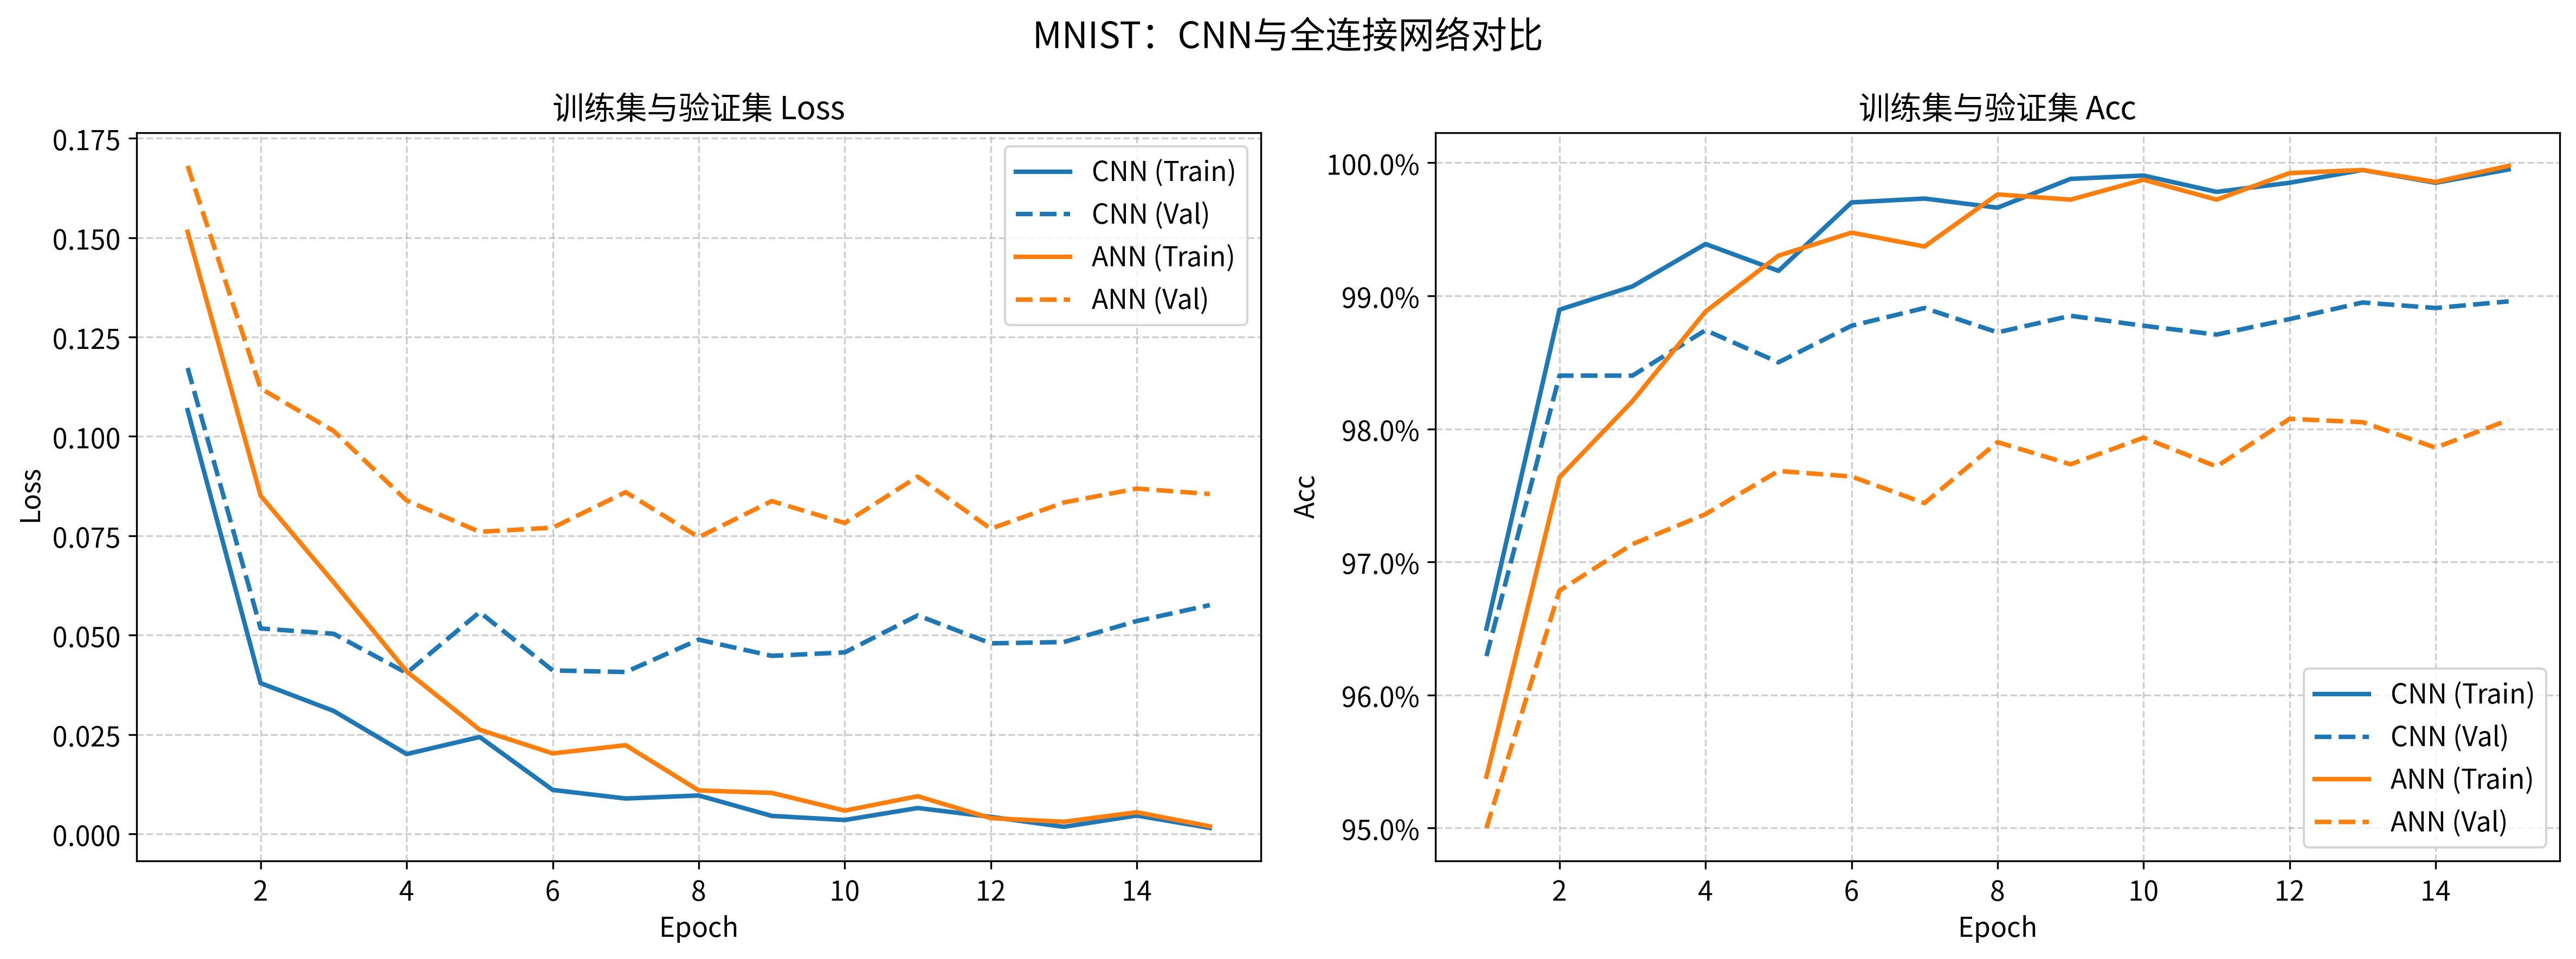

In [17]:
# 传入两种模型的训练记录，绘制MNIST对比结果。
plot_multiple_models_train_result(results_dict, 'MNIST：CNN与全连接网络对比')


In [18]:
# 在独立测试集上计算Loss、Acc和各类别的预测概率。
# 对固定测试集评估；该函数只在所有候选模型与最佳轮次确定后调用。
def evaluate_model(model, batch=128):
    model.eval()
    test_correct, test_num, test_total_loss_sum = 0, 0, 0.0
    test_result, test_probs = [], []
    test_loader = DataLoader(TensorDataset(x_test_tensor, y_test_tensor),
                             batch_size=batch, shuffle=False)
    # 测试阶段关闭梯度计算，并按原顺序收集每个样本的预测。
    with torch.no_grad():
        for batch_x, batch_y in test_loader:
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)
            test_preds = model(batch_x)
            loss = criterion(test_preds, batch_y)
            # 累计Loss总和与预测正确数，最终除以完整测试集样本数。
            test_total_loss_sum += loss.item() * batch_y.size(0)
            predicted_classes = test_preds.argmax(dim=1) # 最大logit对应预测类别
            test_correct += (predicted_classes == batch_y).sum().item()
            test_num += batch_y.size(0)
            test_result += predicted_classes.cpu().tolist()
            test_probs += test_preds.softmax(dim=1).cpu().tolist() # 仅在展示概率时使用Softmax

    # 结果表保留预测标签与10列概率，attrs中保存整体测试指标。
    result_df = pd.DataFrame(test_result, columns=['Predict'])
    prob_df = pd.DataFrame(test_probs, columns=[f'Prob_{i}' for i in range(10)])
    result_df = pd.concat([result_df, prob_df], axis=1)
    result_df.attrs['Loss'] = test_total_loss_sum / test_num
    result_df.attrs['Acc'] = test_correct / test_num
    print(f"测试集 Loss: {result_df.attrs['Loss']:.4f}，Acc: {result_df.attrs['Acc']:.2%}")
    return result_df


#### 三、验证集选模与独立测试
（1）先按最佳验证 Acc 排序（相同则比较验证 Loss），固定最终模型，再统一测试。
测试集不参与训练、最佳轮次选择或结构选择。参数量与训练时间同时列出，便于比较识别效果和计算代价。


In [19]:
# 汇总各模型最佳验证轮次的结果，先固定最终模型。
validation_rows = []
for name, current_model in models.items():
    history = results_dict[name]
    # 读取训练时选中的最佳轮次，而不是直接使用最后一轮。
    best = history.iloc[current_model.best_epoch - 1]
    validation_rows.append({
        'Model': name, 'Parameters': sum(p.numel() for p in current_model.parameters()),
        'Best_Epoch': current_model.best_epoch,
        'Val_Loss': float(best['Val_Loss']), 'Val_Acc': float(best['Val_Acc']),
        'Seconds': current_model.training_seconds
    })
# 验证Acc越高越优；相同时选择验证Loss较小的结构。
validation_table = pd.DataFrame(validation_rows).sort_values(
    ['Val_Acc', 'Val_Loss'], ascending=[False, True]).reset_index(drop=True)
best_model_name = validation_table.iloc[0]['Model']
# 固定最终模型，后面的可视化和模型保存均使用它。
model = models[best_model_name]
print('按验证集选定的最终模型：', best_model_name)
display(validation_table.style.format({
    'Val_Loss': '{:.4f}', 'Val_Acc': '{:.2%}', 'Seconds': '{:.1f}'
}).hide(axis='index'))


按验证集选定的最终模型： CNN


Model,Parameters,Best_Epoch,Val_Loss,Val_Acc,Seconds
CNN,421642,15,0.0576,98.96%,7.4
ANN,407050,12,0.0768,98.08%,5.6


In [20]:
# 对已训练的两个模型统一测试，并保存逐样本预测与比较表。
predictions, comparison_rows = {}, []
y_true = y_test
# 所有结构已按验证集定好权重，此处才开始读取测试指标。
for name, current_model in models.items():
    print('\n模型：', name)
    result = evaluate_model(current_model)
    predictions[name] = result
    result.to_csv(OUTPUT_DIR / f'{name}_test_predictions.csv', index=False)
    row = validation_table.loc[validation_table['Model'] == name].iloc[0].to_dict()
    comparison_rows.append({**row, 'Test_Loss': result.attrs['Loss'],
                            'Test_Acc': result.attrs['Acc']})
# 汇总验证与测试表现；逐样本预测另存CSV，便于检查误分类。
comparison_table = pd.DataFrame(comparison_rows)
comparison_table.to_csv(OUTPUT_DIR / 'comparison.csv', index=False)
display(comparison_table.style.format({
    'Val_Loss': '{:.4f}', 'Val_Acc': '{:.2%}', 'Test_Loss': '{:.4f}',
    'Test_Acc': '{:.2%}', 'Seconds': '{:.1f}'
}).hide(axis='index'))
test_result = predictions[best_model_name]
display(test_result.head(10).round(4))



模型： CNN
测试集 Loss: 0.0387，Acc: 99.10%



模型： ANN
测试集 Loss: 0.0774，Acc: 98.00%


Model,Parameters,Best_Epoch,Val_Loss,Val_Acc,Seconds,Test_Loss,Test_Acc
CNN,421642,15,0.0576,98.96%,7.4,0.0387,99.10%
ANN,407050,12,0.0768,98.08%,5.6,0.0774,98.00%


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
5,1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
7,9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
8,5,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
9,9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


（2）查看最终模型的类别表现、混淆矩阵与部分识别结果。
对角线以外的位置表示误分类；分类报告可观察整体 Acc 是否掩盖某些类别的识别困难。


              precision    recall  f1-score   support

           0     0.9899    0.9959    0.9929       980
           1     0.9956    0.9991    0.9974      1135
           2     0.9942    0.9932    0.9937      1032
           3     0.9930    0.9891    0.9911      1010
           4     0.9939    0.9949    0.9944       982
           5     0.9768    0.9933    0.9850       892
           6     0.9989    0.9823    0.9905       958
           7     0.9864    0.9883    0.9874      1028
           8     0.9918    0.9887    0.9902       974
           9     0.9881    0.9841    0.9861      1009

    accuracy                         0.9910     10000
   macro avg     0.9909    0.9909    0.9909     10000
weighted avg     0.9910    0.9910    0.9910     10000



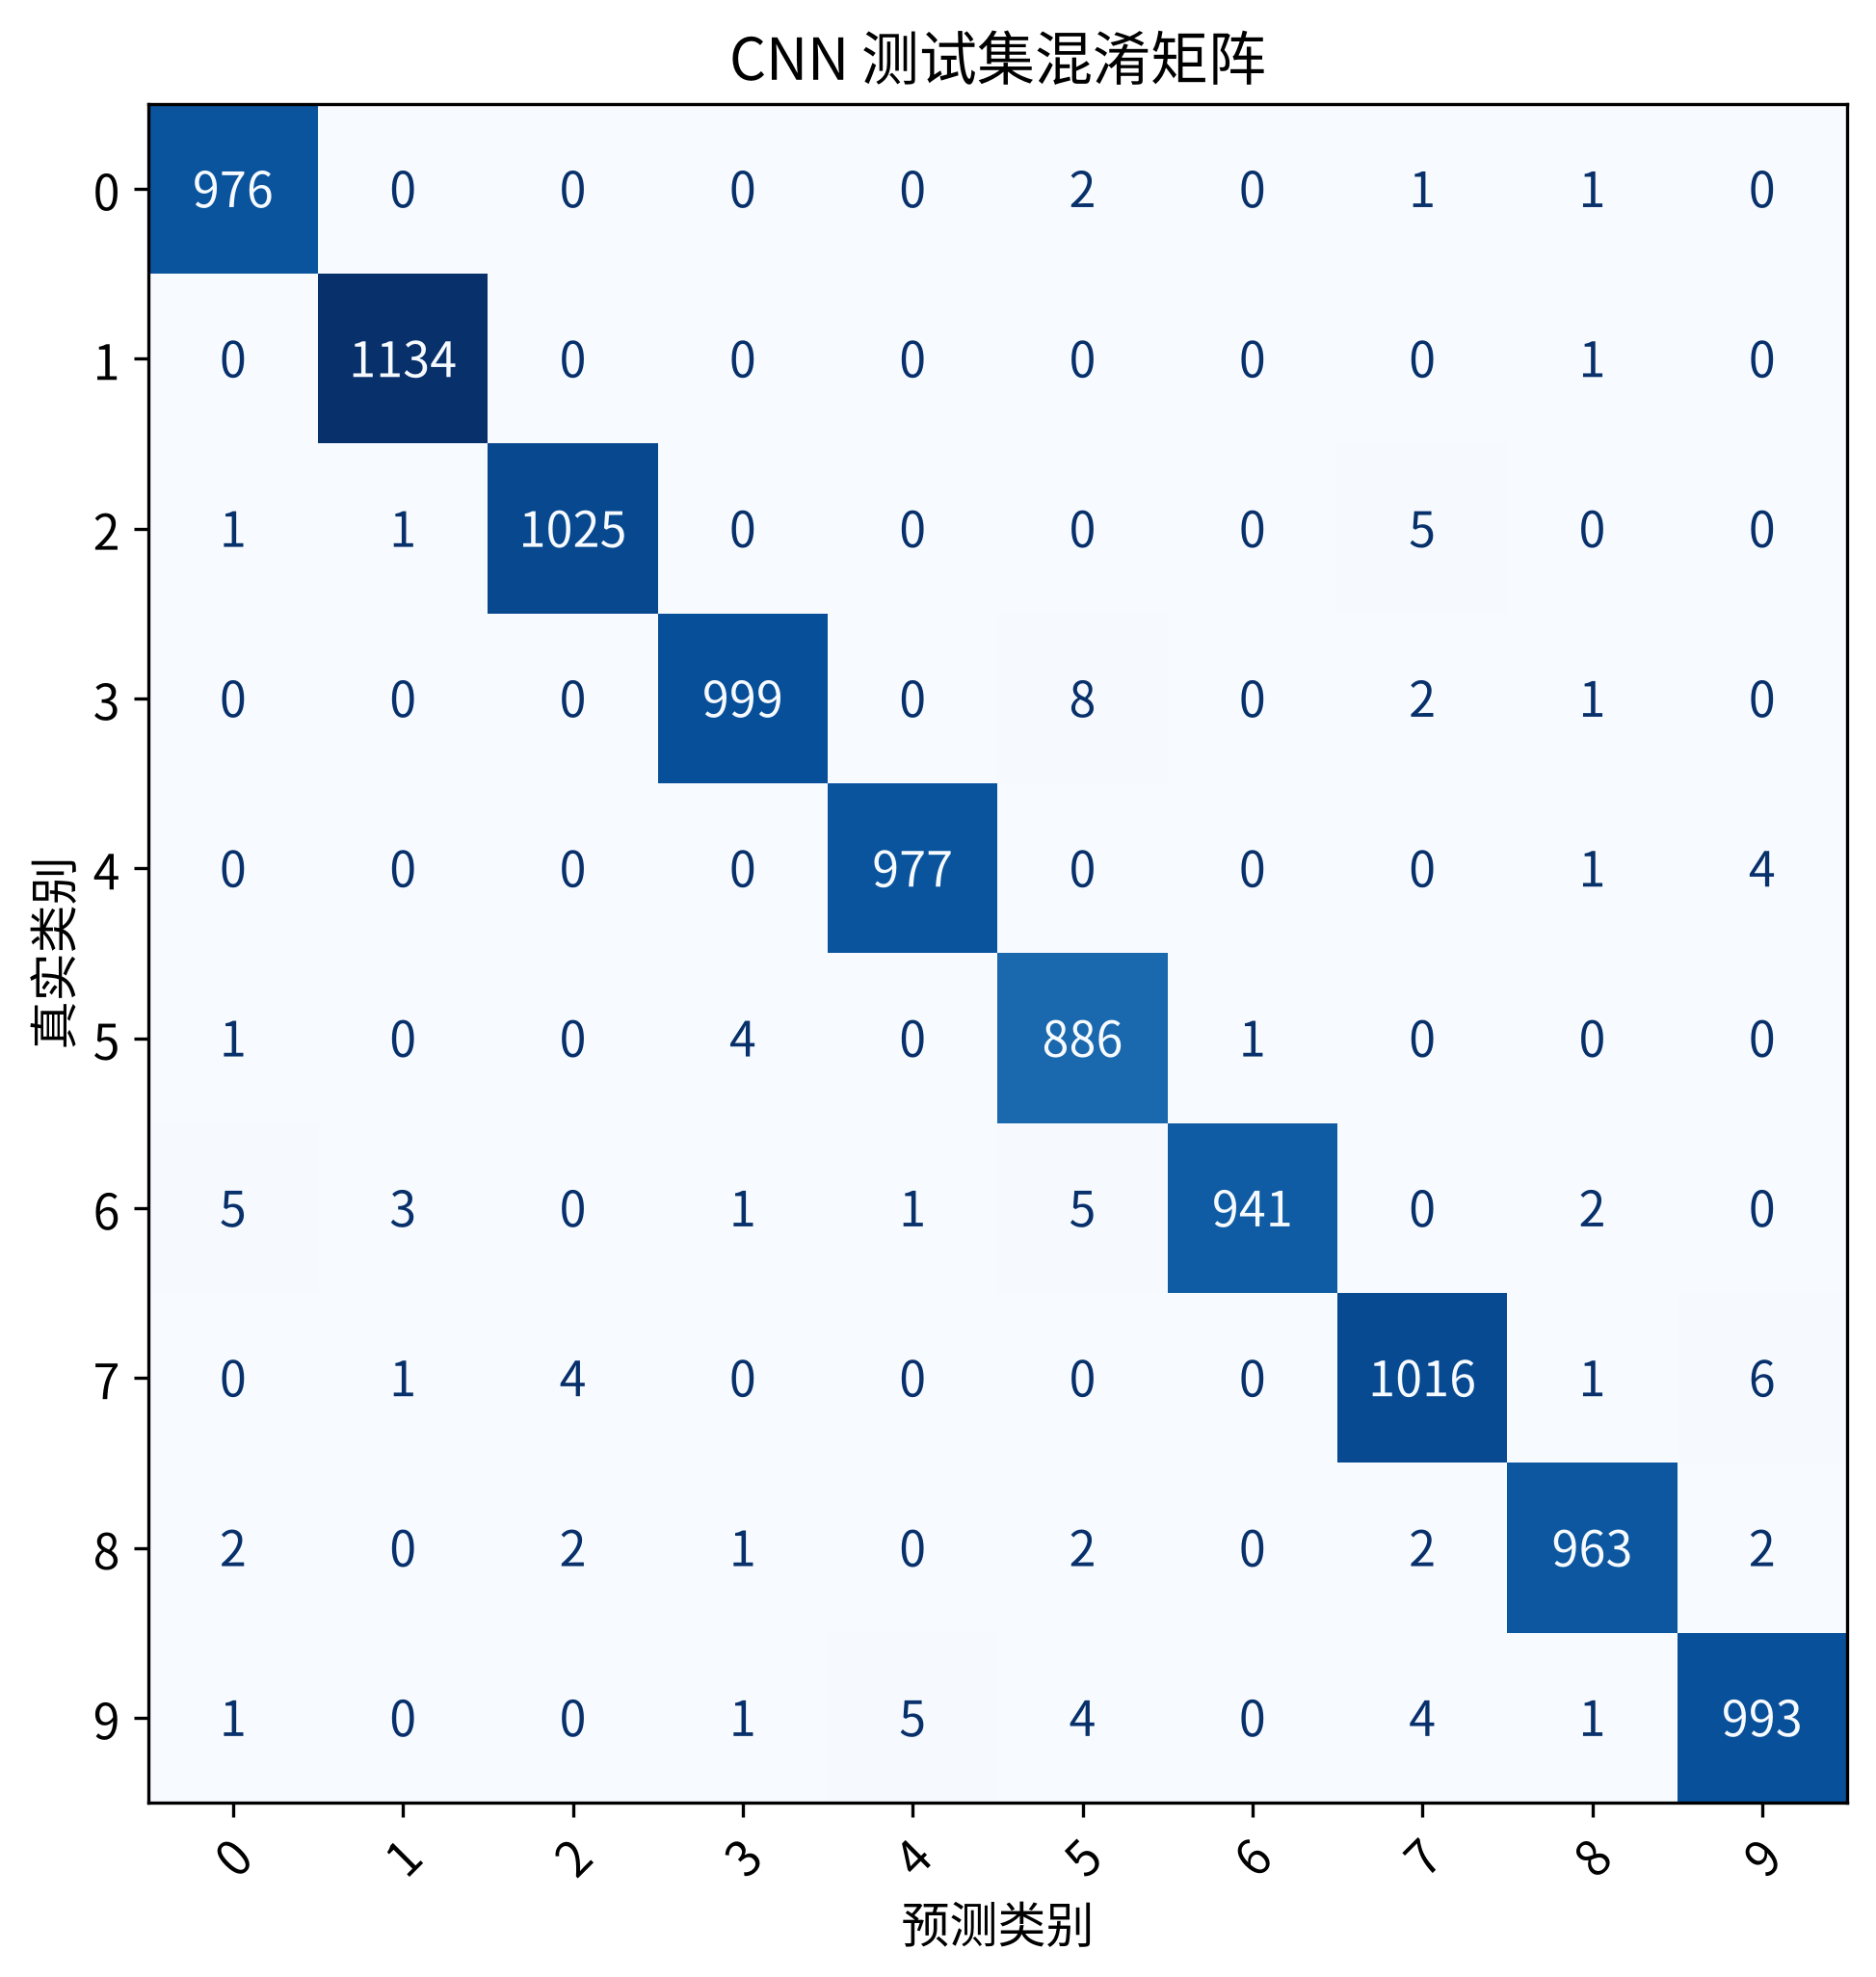

In [21]:
# 输出各数字的分类指标，并绘制最终模型的测试集混淆矩阵。
class_names = [str(i) for i in range(10)]
# 分类报告分别给出各类别的Precision、Recall和F1。
print(classification_report(y_true, test_result['Predict'], labels=list(range(10)),
                            target_names=class_names, digits=4, zero_division=0))
fig, ax = plt.subplots(figsize=(8, 7))
# 混淆矩阵的行是真实类别，列是预测类别，非对角线表示错误。
ConfusionMatrixDisplay.from_predictions(
    y_true, test_result['Predict'], labels=list(range(10)),
    display_labels=class_names, cmap='Blues', ax=ax, colorbar=False,
    xticks_rotation=45
)
ax.set_title(f'{best_model_name} 测试集混淆矩阵')
ax.set_xlabel('预测类别')
ax.set_ylabel('真实类别')
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'confusion_matrix.png', bbox_inches='tight')
plt.show()


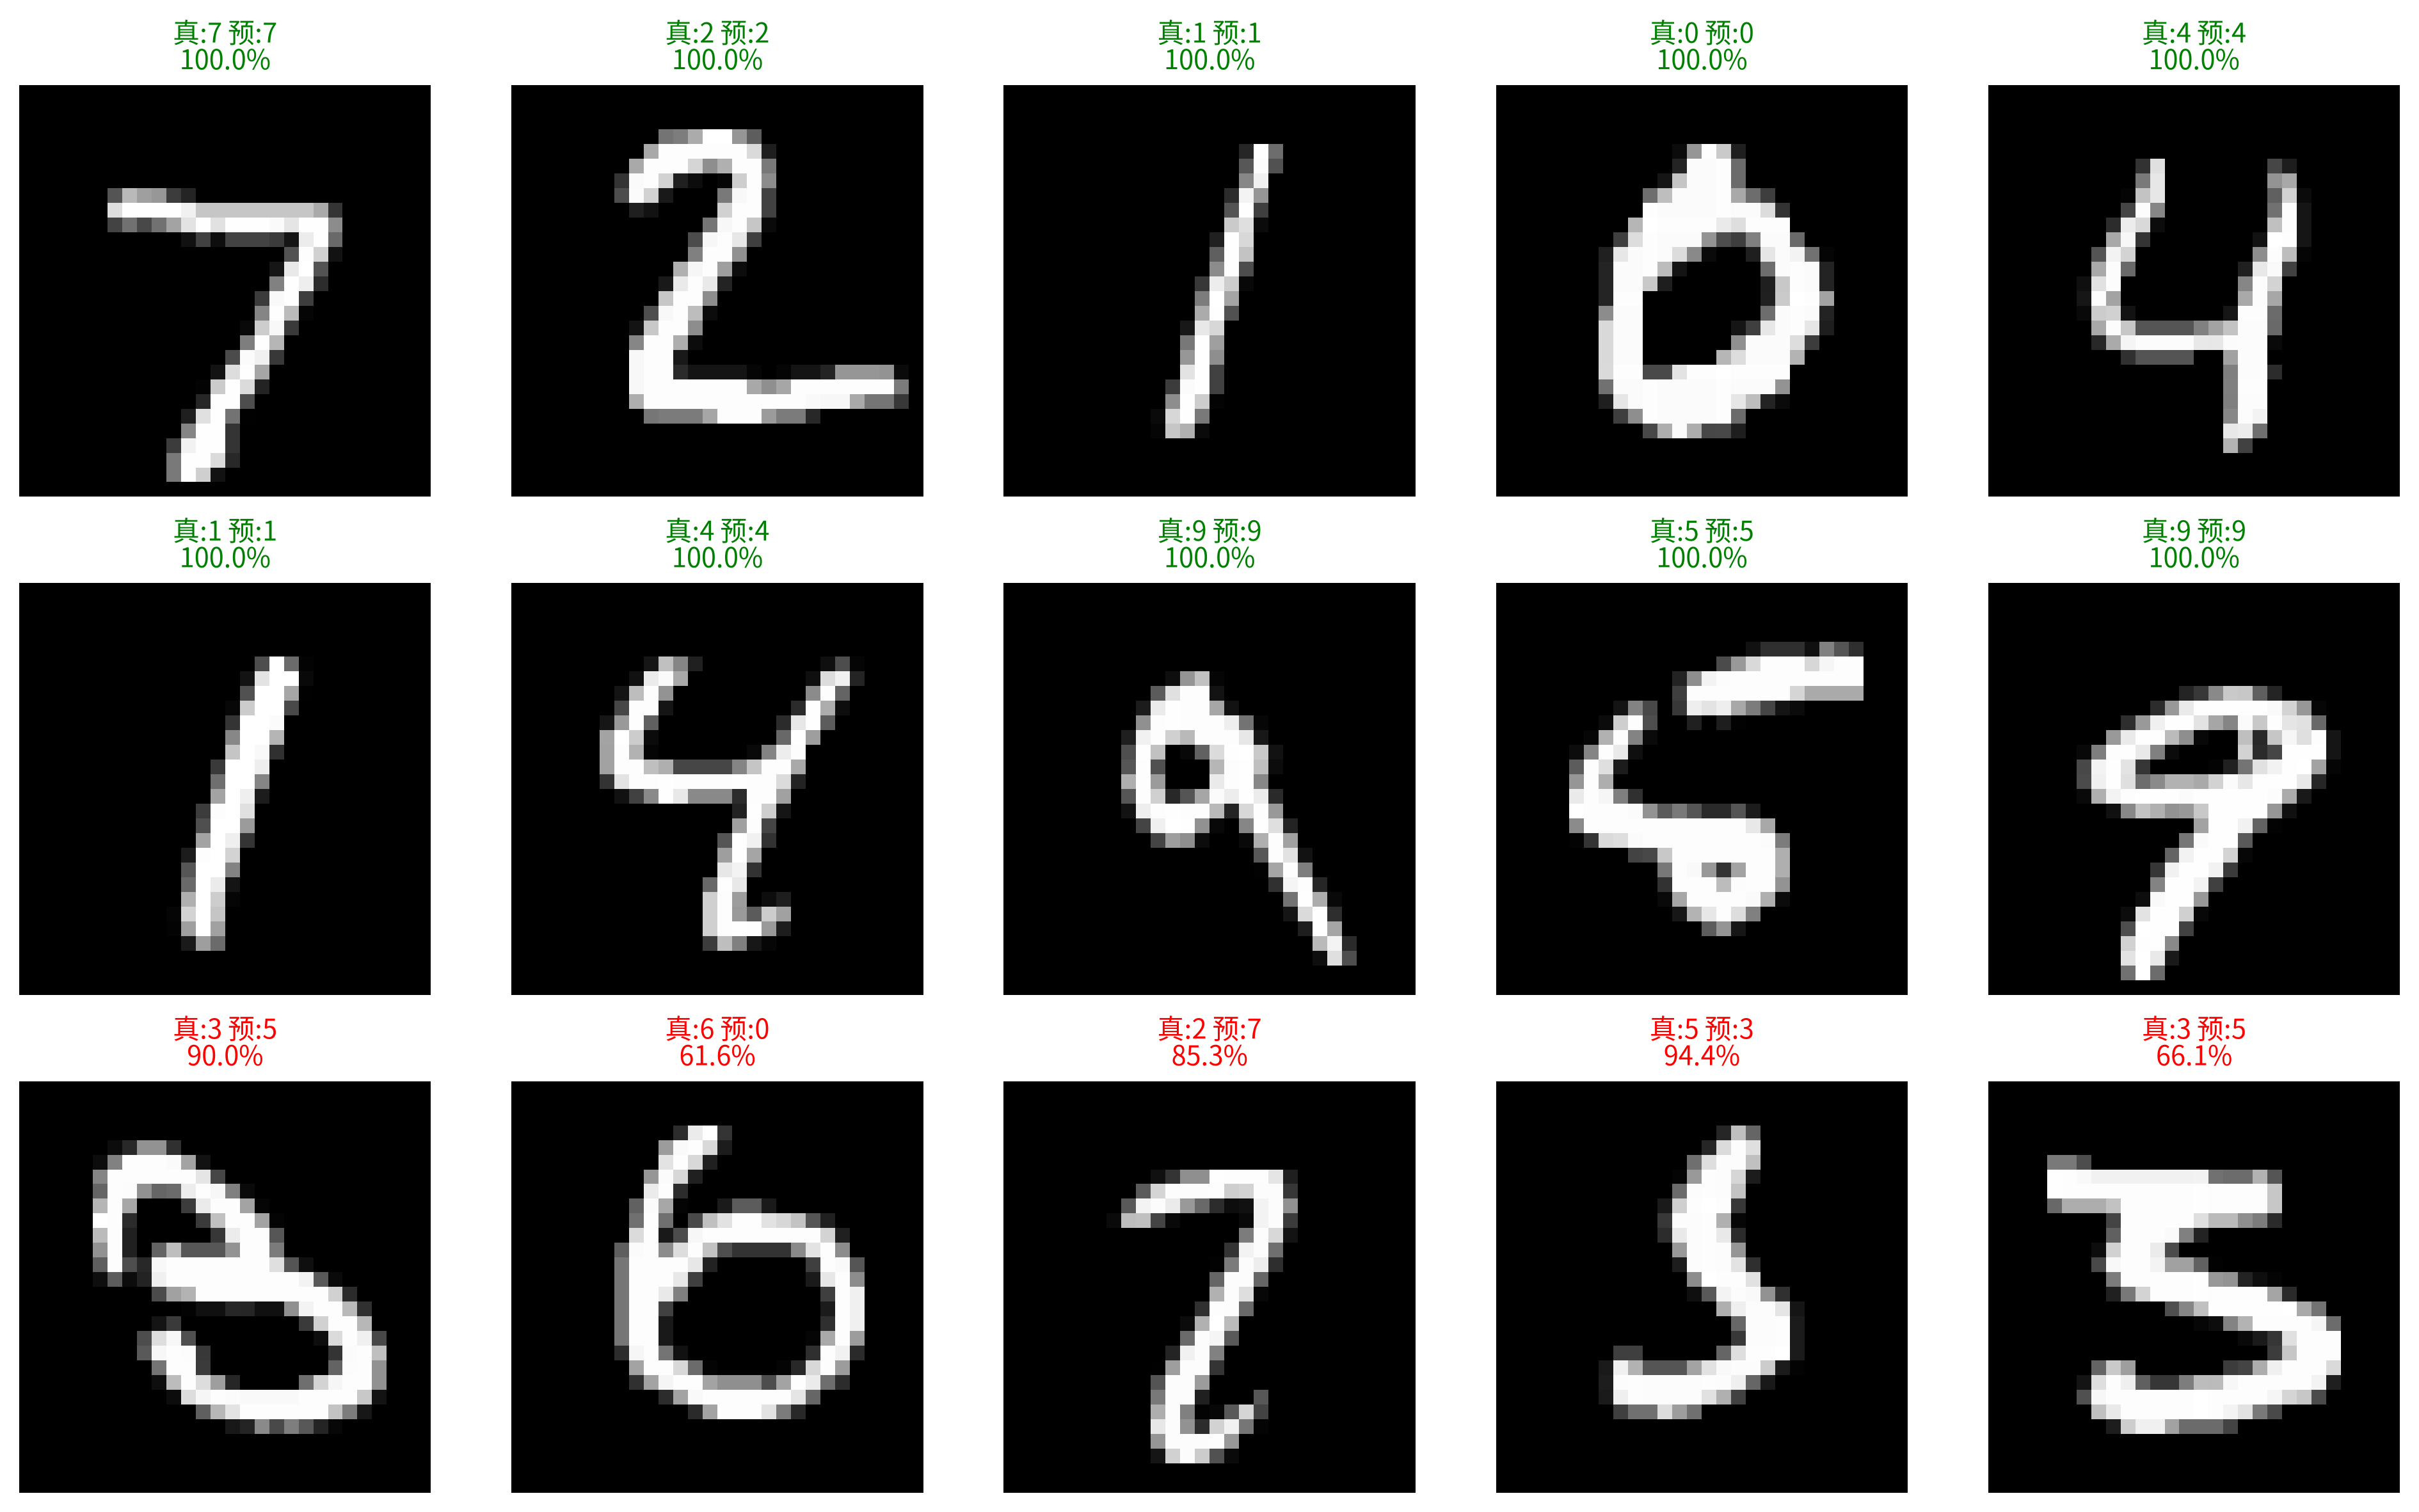

In [22]:
# 展示测试图像的真实数字、预测数字和预测类别的概率。
# 前十张图与最多五张误分类样本，均来自独立测试集。
wrong = np.flatnonzero(test_result['Predict'].to_numpy() != y_true)
# 前十张图用于普通预测展示，另取最多五张误分类样本观察错误。
sample_indices = np.concatenate([np.arange(10), wrong[:5]])
fig, axes = plt.subplots(3, 5, figsize=(13, 8))
for ax in axes.flat:
    ax.axis('off')
for ax, index in zip(axes.flat, sample_indices):
    predicted = int(test_result.iloc[index]['Predict'])
    confidence = float(test_result.iloc[index][f'Prob_{predicted}']) # 预测类别的Softmax概率
    ax.imshow(x_test[index, 0], cmap='gray')
    # 绿色表示预测正确，红色表示误分类；高概率也可能出错。
    ax.set_title(f'真:{class_names[int(y_true[index])]} 预:{class_names[predicted]}\n{confidence:.1%}',
                 color='green' if predicted == y_true[index] else 'red', fontsize=10)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'prediction_examples.png', bbox_inches='tight')
plt.show()


（3）保存验证集选中的最终模型，并重新加载检查预测是否一致。
权重、结构名称、输入形状、预处理方式和类别顺序一并保存，后续真实图片必须使用同样的预处理。


In [23]:
# 保存最终权重与预处理信息，再重新加载检查预测是否一致。
experiment_config = {
    'dataset': 'MNIST', 'split_sizes': [len(y_train), len(y_val), len(y_test)],
    'input_shape': [1, 28, 28], 'normalization': 'float32 / 255',
    'optimizer': 'RMSprop', 'learning_rate': 0.001, 'epochs': 15, 'batch': 128,
    'seed': 42, 'validation_ratio': 0.2, 'classes': class_names,
    'best_model': best_model_name, 'best_epoch': int(model.best_epoch),
    'selection': 'maximum validation accuracy; minimum validation loss for ties'
}
# 同时保存state_dict和输入配置，便于使用相同结构和预处理恢复模型。
torch.save({'model_state_dict': model.state_dict(), 'config': experiment_config},
           OUTPUT_DIR / 'best_model.pt')
# 从刚保存的文件重建模型，再在同一批输入上比较输出。
checkpoint = torch.load(OUTPUT_DIR / 'best_model.pt', map_location=device, weights_only=True)
reloaded = {'CNN': CNN, 'ANN': ANN}[checkpoint['config']['best_model']]().to(device)
reloaded.load_state_dict(checkpoint['model_state_dict'])
reloaded.eval()
with torch.no_grad():
    sample_x = x_test_tensor[:32].to(device)
    # 加载前后logits应在浮点容差内一致，否则说明恢复过程有误。
    assert torch.allclose(model(sample_x), reloaded(sample_x), atol=1e-6)
# 保存实验配置和比较结果，作为本次实测记录。
summary = {'config': experiment_config, 'comparison': comparison_table.to_dict(orient='records')}
(OUTPUT_DIR / 'summary.json').write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print('已保存并验证最佳模型：', OUTPUT_DIR / 'best_model.pt')


已保存并验证最佳模型： outputs/best_model.pt


#### 四、实验过程与模型性能分析


##### （1）实测结果

两个模型均使用48000张训练图像、12000张固定验证图像和10000张独立测试图像；优化器为RMSprop，学习率0.001，batch=128，训练15轮。

| 模型 | 参数量 | 最佳轮次 | 验证Loss | 验证Acc | 测试Loss | 测试Acc |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: |
| CNN | 421,642 | 15 | 0.0576 | 98.96% | 0.0387 | 99.10% |
| ANN | 407,050 | 12 | 0.0768 | 98.08% | 0.0774 | 98.00% |

按验证集选择的最终模型为 **CNN**，保存的是第15轮权重。CNN测试准确率比全连接网络高 **1.10个百分点**，说明利用图像局部空间关系有助于本次手写数字识别。CNN与ANN训练耗时分别约7.4秒和5.6秒，耗时受共享GPU负载影响。


##### （2）结果解释与泛化分析

CNN测试Acc为99.10%，ANN为98.00%，本次CNN高1.10个百分点。但CNN参数量为421,642，略多于ANN的407,050；这说明本例的收益主要来自卷积的空间结构假设，不能归因于参数更少。两者都已经充分拟合训练数据，验证与测试结果支持CNN在本次划分下有更好的泛化表现。

CNN在最佳轮次的训练Acc为99.95%，验证Acc为98.96%，两者差距为0.99个百分点；ANN在最佳轮次的训练Acc为99.92%，验证Acc为98.08%，两者差距为1.85个百分点。训练／验证差距说明仍存在过拟合，增加网络深度并不会自动解决泛化问题；后续可在独立的调参阶段比较数据增强与正则化。